# Stastistical modeling and computation
## Week 1 Assignment - Part 3: Dimensionality reduction

In this assignment you will work with the life expectancy dataset. The goal is to apply the 3 methods discussed in the lectures to reduce the dimensions of the dataset and to inspect patterns in the data.

Start by importing neccessary libraries. You can add more if you want.


In [1]:
# Importing the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1. Getting started

The first step of the analysis is to prepare the dataset. 
Perform the following steps:

1. Read in the dataset.
2. Select one year in the dataset to use (your choice which year it is). You can drop the rest of the data.
3. Separate the variables `Year`, `Country` and `Status` from the other variables. They will not be used in the DR. You will need  `Country` and `Status` later.
4. Scale and center the remaining variables. You can use `StandardScaler` method from `scikit-learn` to do this.

In [2]:
# Read in the dataset 
df= pd.read_csv('LifeExpectancy.csv')            

In [3]:
# Select one year to use for the analysis 
df_sel = df[df['Year'] == 2015]

In [4]:
# Separate the varables Year, Country and Status from the dataset.
year=df_sel['Year']
country=df_sel['Country']
status=df_sel['Status']
data=df_sel.drop(['Year','Country','Status'], axis=1)

In [5]:
# Import the StandardScaler
from sklearn.preprocessing import StandardScaler 
scaler = StandardScaler()

# Scale the dataset
scaled_data = scaler.fit_transform(data)
scaled_data

array([[-0.81675694,  1.13199499,  0.45769349, ...,  3.06788363,
        -1.40000085, -0.98062563],
       [ 0.76320132, -0.8105657 , -0.28522359, ..., -0.79079582,
         0.49365485,  0.46745278],
       [ 0.491646  , -1.37586114, -0.03359038, ...,  0.29445777,
         0.36651896,  0.53809076],
       ...,
       [-0.73035297,  0.73114913,  0.15813016, ...,  2.12733052,
        -1.26617359, -1.36913448],
       [-1.21174651, -1.23196775,  0.03830482, ...,  0.36680801,
        -0.75093865, -0.13296997],
       [-0.56988846,  1.8822962 , -0.02160785, ...,  0.22210753,
        -1.21264269, -0.90998766]], shape=(183, 19))

**Question**: What is the purpose of scaling and centering the data? Is it neccessary?

Answer: centering subtract the mean of a variable from every value, giving it a mean of zero. With the purpose of making variables easier to intepret models and helping reduce numerical instabilities.

Scaling instead divides the centered values by the standard deviation, giving the variable a standard deviation of 1. With the purpuse of ensure that all the variables contributes equally, preventing dominating variables(with large ranges).

They are both necessary for models that relies on distance(so for PCA). Not necessary for algorithm that compares groups using only one variable.

### 2. Principal Component Analysis

First you will perform PCA on the dataset that you prepared. Perform the following steps:

1. Import the PCA method.
2. Create an instance of the PCA method that results in 2 PCs.
3. Fit the instance to the data and transform it.

You will also plot the datapoints with resepct to the two PC.


In [6]:
# import the PCA method
from sklearn.decomposition import PCA
# create an instance of the PCA method that results in 2 PCs
pca= PCA(n_components=2)
# fit it to the data and transform the data.
pca_result= pca.fit_transform(scaled_data)
experienced_variance= pca.explained_variance_ratio_
print("Explained variance by each component: ", experienced_variance)



Explained variance by each component:  [0.32492176 0.15421923]


In [13]:
# inspect the PCA loadings
loadings= pca.components_
loading_df= pd.DataFrame(loadings.T, columns=['PC1','PC2'], index=data.columns)
loading_df

,PC1,PC2
Life expectancy,0.352949,0.151085
Adult Mortality,-0.277824,-0.138819
infant deaths,-0.209105,0.441833
Alcohol,0.069946,-0.028923
percentage expenditure,0.012011,0.011446
Hepatitis B,0.192996,0.251903
Measles,-0.127734,0.430781
BMI,0.253464,-0.009999
under-five deaths,-0.216499,0.425539
Polio,0.238784,0.199797


**Question**: How much of the variance do the two PCs explain?

Answer: [0.32492176 0.15421923]

**Question (Extra)**: Inspect the loadings of the two PCs with respect to the variables. How do the variables align?

Answer: The first principal component has high positive loadings for variables such as 'Adult Mortality', 'Infant Deaths', 'HIV/AIDS', and 'Diphtheria', indicating that these factors contribute significantly to the variance captured by this component. On the other hand, it has negative loadings for 'Life expectancy' and 'GDP', suggesting an inverse relationship with these variables. The second principal component shows a different pattern, with high positive loadings for 'Alcohol', 'BMI', and 'Polio', while having negative loadings for 'HIV/AIDS' and 'Infant Deaths'. This indicates that the second component captures variance related to lifestyle and health factors that are distinct from those represented in the first component. 

Now plot the data with resepct to the two PCs.  Label the datapoints with the country name.  
a. Color the points depending on the variable `status`.  
b. (Bonus) Color the points depending on continent. This variable is not in the dataset so you will have to add it. 

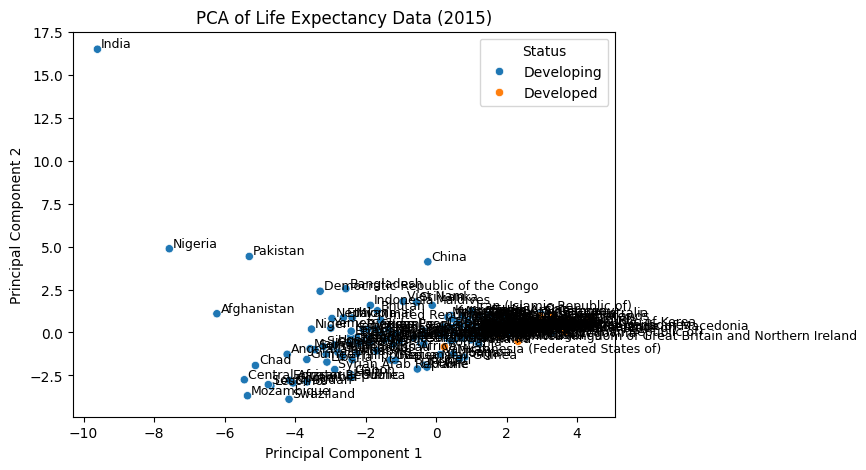

In [7]:
# plot the PCA results with country labels
#a
plt.figure(figsize=(7,5))
sns.scatterplot(x=pca_result[:,0], y=pca_result[:,1], hue=status)
for i, country in enumerate(country):
    plt.text(pca_result[i,0]+0.1, pca_result[i,1]+0.1, country, fontsize=9) 
plt.title('PCA of Life Expectancy Data (2015)')     
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2') 
plt.show()

C:\Users\Utente\AppData\Local\Temp\ipykernel_20796\4104154215.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sel['Continent'] = df_sel['Country'].apply(country_to_continent)


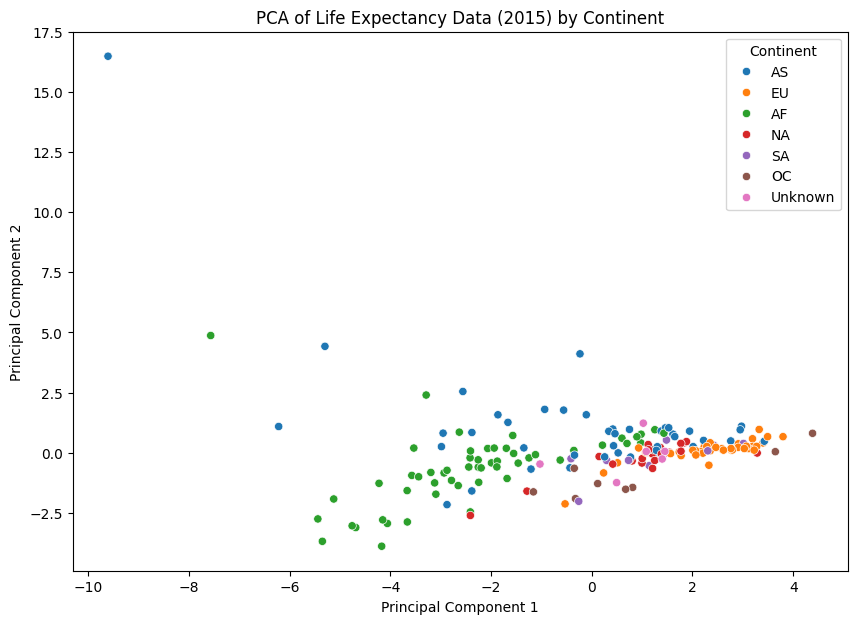

In [30]:
#add continent variables to the dataset
import pycountry_convert as pc
def country_to_continent(country_name):
    try:
        country_code = pc.country_name_to_country_alpha2(country_name)
        continent_code = pc.country_alpha2_to_continent_code(country_code)
        return continent_code
    except:
        return 'Unknown'
df_sel['Continent'] = df_sel['Country'].apply(country_to_continent)

# plot the PCA results with continent information(coloring the poitnss based on continent)
plt.figure(figsize=(10,7))
sns.scatterplot(x=pca_result[:,0], y=pca_result[:,1], hue=df_sel['Continent'])
plt.title('PCA of Life Expectancy Data (2015) by Continent')    
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

**Question**: Explain the relationship between the `status` and the two PCs.

Answer: 
The PCA plot reveals a clear separation between countries based on their status (Developed vs Developing).
Developed countries tend to cluster together in a specific region of the PCA space, characterized by higher values on the first principal component (PC1) and lower values on the second principal component (PC2). This suggests that developed countries generally have better health indicators. In contrast, developing countries are more dispersed across the PCA space, indicating greater variability in health outcomes.

**Question**: (Bonus) Eplain the relationship between continent and the two PCs.

Answer: African countries are predominantly located in the lower left quadrant of the PCA space, characterized by lower values on both principal components. This suggests that African countries generally have poorer health indicators compared to other continents. In contrast, European and North American countries cluster in the upper right quadrant, indicating better health outcomes. Asian and South American countries are more dispersed across the PCA space(wider range).

### 3. Multidimensional Scaling

Second you will perform MDS on the dataset that you prepared. Perform the following steps:

1. Import the MDS method.
2. Create an instance of the MDS method that results in 2 dimensions. It should be metric MDS.  
3. Fit the instance to the data and transform it.  
4. Plot the datapoints with resepct to the two dimensions.  
    a. Color the datapoints w.r.t `status``.  
    b. (Bonus) Color the datapoints w.r.t. continent.

In [16]:
# import the MDS method
from sklearn.manifold import MDS
# create an instance of a metric MDS method with 2 dimensions
mds = MDS(n_components=2, random_state=42)
# fit it to the data and transform the data. 
mds_result = mds.fit_transform(scaled_data)

c:\Users\Utente\Desktop\universitaMagistrale\2nd year 1st semester\statisticalComputation\assignment1\venv\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


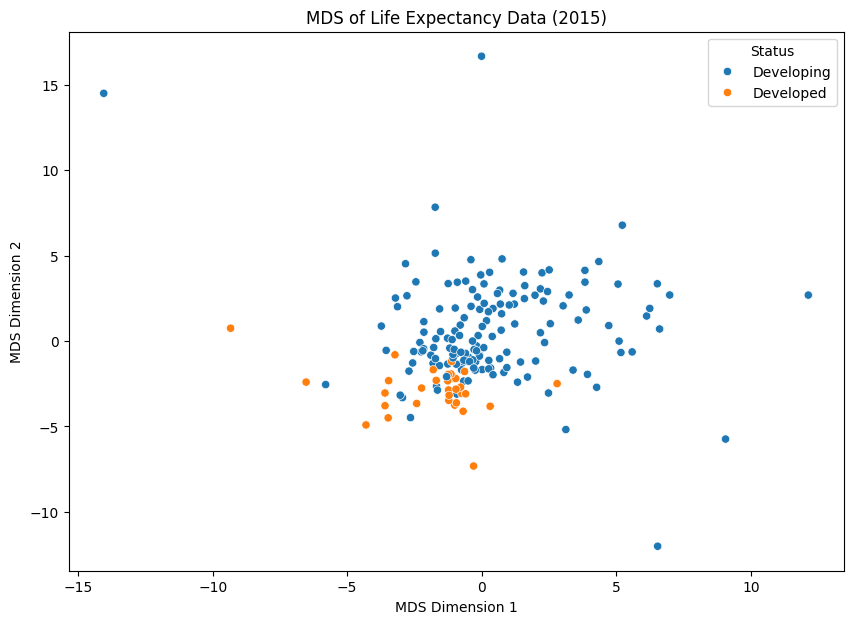

In [17]:
# plot the MDS results colored by the status of the country
plt.figure(figsize=(10,7))
sns.scatterplot(x=mds_result[:,0], y=mds_result[:,1], hue=status)
plt.title('MDS of Life Expectancy Data (2015)')
plt.xlabel('MDS Dimension 1')
plt.ylabel('MDS Dimension 2')
plt.show()

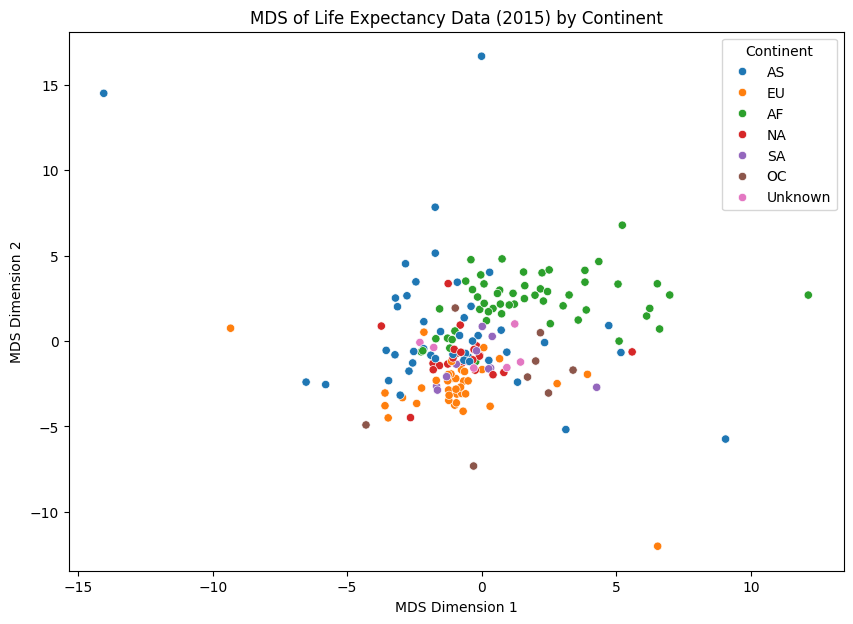

In [18]:
#plot the MDS results colored by the continent of the country
plt.figure(figsize=(10,7))
sns.scatterplot(x=mds_result[:,0], y=mds_result[:,1], hue=df_sel['Continent'])
plt.title('MDS of Life Expectancy Data (2015) by Continent')
plt.xlabel('MDS Dimension 1')
plt.ylabel('MDS Dimension 2')
plt.show()

**Question**: Explain the relationship between the `status` and the two dimenstion of the MDS.

Answer: The MDS plot shows a similar pattern to the PCA results, with a noticeable separation between developed and developing countries. Developed countries cluster together in a specific region of the MDS space, indicating that they share similar health profiles. Developing countries, on the other hand, are more scattered throughout the MDS space, reflecting a wider range of health outcomes and conditions. This dispersion suggests that developing countries have more variability in their health indicators compared to developed countries.

**Question**: (Bonus) Eplain the relationship between continent and the two dimension of the MDS.

Answer: The MDS plot reveals distinct clustering patterns based on continent. African countries are primarily located in one region of the MDS space, indicating similar health profiles among them. European and North American countries cluster together in another region, suggesting better health outcomes. Asian and South American countries are more dispersed across the MDS space, reflecting a wider range of health conditions and outcomes within these continents.

Now perform the same steps but use the non-metric MDS. 

c:\Users\Utente\Desktop\universitaMagistrale\2nd year 1st semester\statisticalComputation\assignment1\venv\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


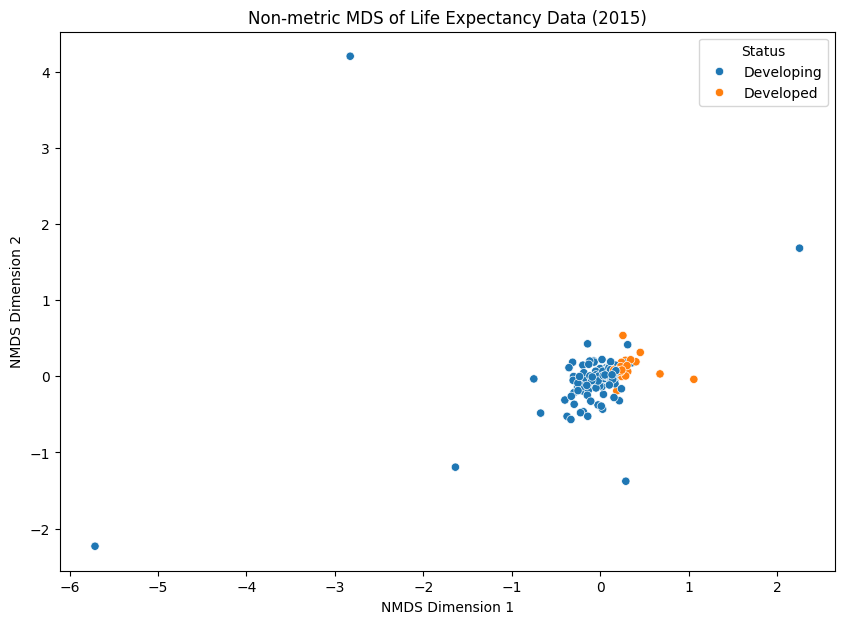

In [19]:
# Perform non-metric MDS and plot the result
nmds = MDS(n_components=2, metric=False, random_state=42)
nmds_result = nmds.fit_transform(scaled_data)
plt.figure(figsize=(10,7))
sns.scatterplot(x=nmds_result[:,0], y=nmds_result[:,1], hue=status)
plt.title('Non-metric MDS of Life Expectancy Data (2015)')
plt.xlabel('NMDS Dimension 1')
plt.ylabel('NMDS Dimension 2')
plt.show()

**Question**: Does the non-metric MDS result in a differnt solution? How do the non-metric and metric MDS compare? 

Answer:
The non-metric MDS produces a different arrangement of the data points compared to the metric MDS. While both methods aim to preserve the relative distances between points, non-metric MDS focuses on maintaining the rank order of distances rather than the actual distances themselves.


### 4. t-SNE

Third you will perform t-SNE on the dataset that you prepared. Perform the following steps:

1. Import the t-SNE method.
2. Create an instance of the t-SNE method that results in 2 dimensions. Use default parameter values.  
3. Fit the instance to the data and transform it.  
4. Plot the datapoints with resepct to the two dimensions.   

In [39]:
# import the t-SNE method
from sklearn.manifold import TSNE
# create an instance of a metric t-SNE method with 2 dimensions
tsne = TSNE(n_components=2, metric='cosine', random_state=42)

# fit it to the data and transform the data. 
tsne_result = tsne.fit_transform(scaled_data)

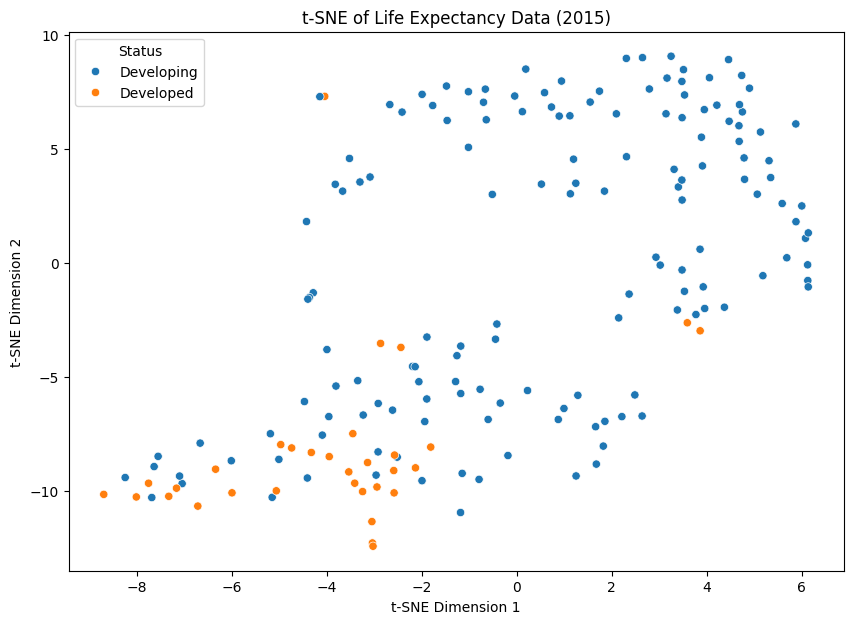

In [40]:
# plot the t-SNE results 
plt.figure(figsize=(10,7))
sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=status)
plt.title('t-SNE of Life Expectancy Data (2015)')     
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2') 
plt.show()

Next, play around with the values of the parameters `perplexity` and `learning_rate`. Fit different instances of t-SNE to the data and plot the results. 

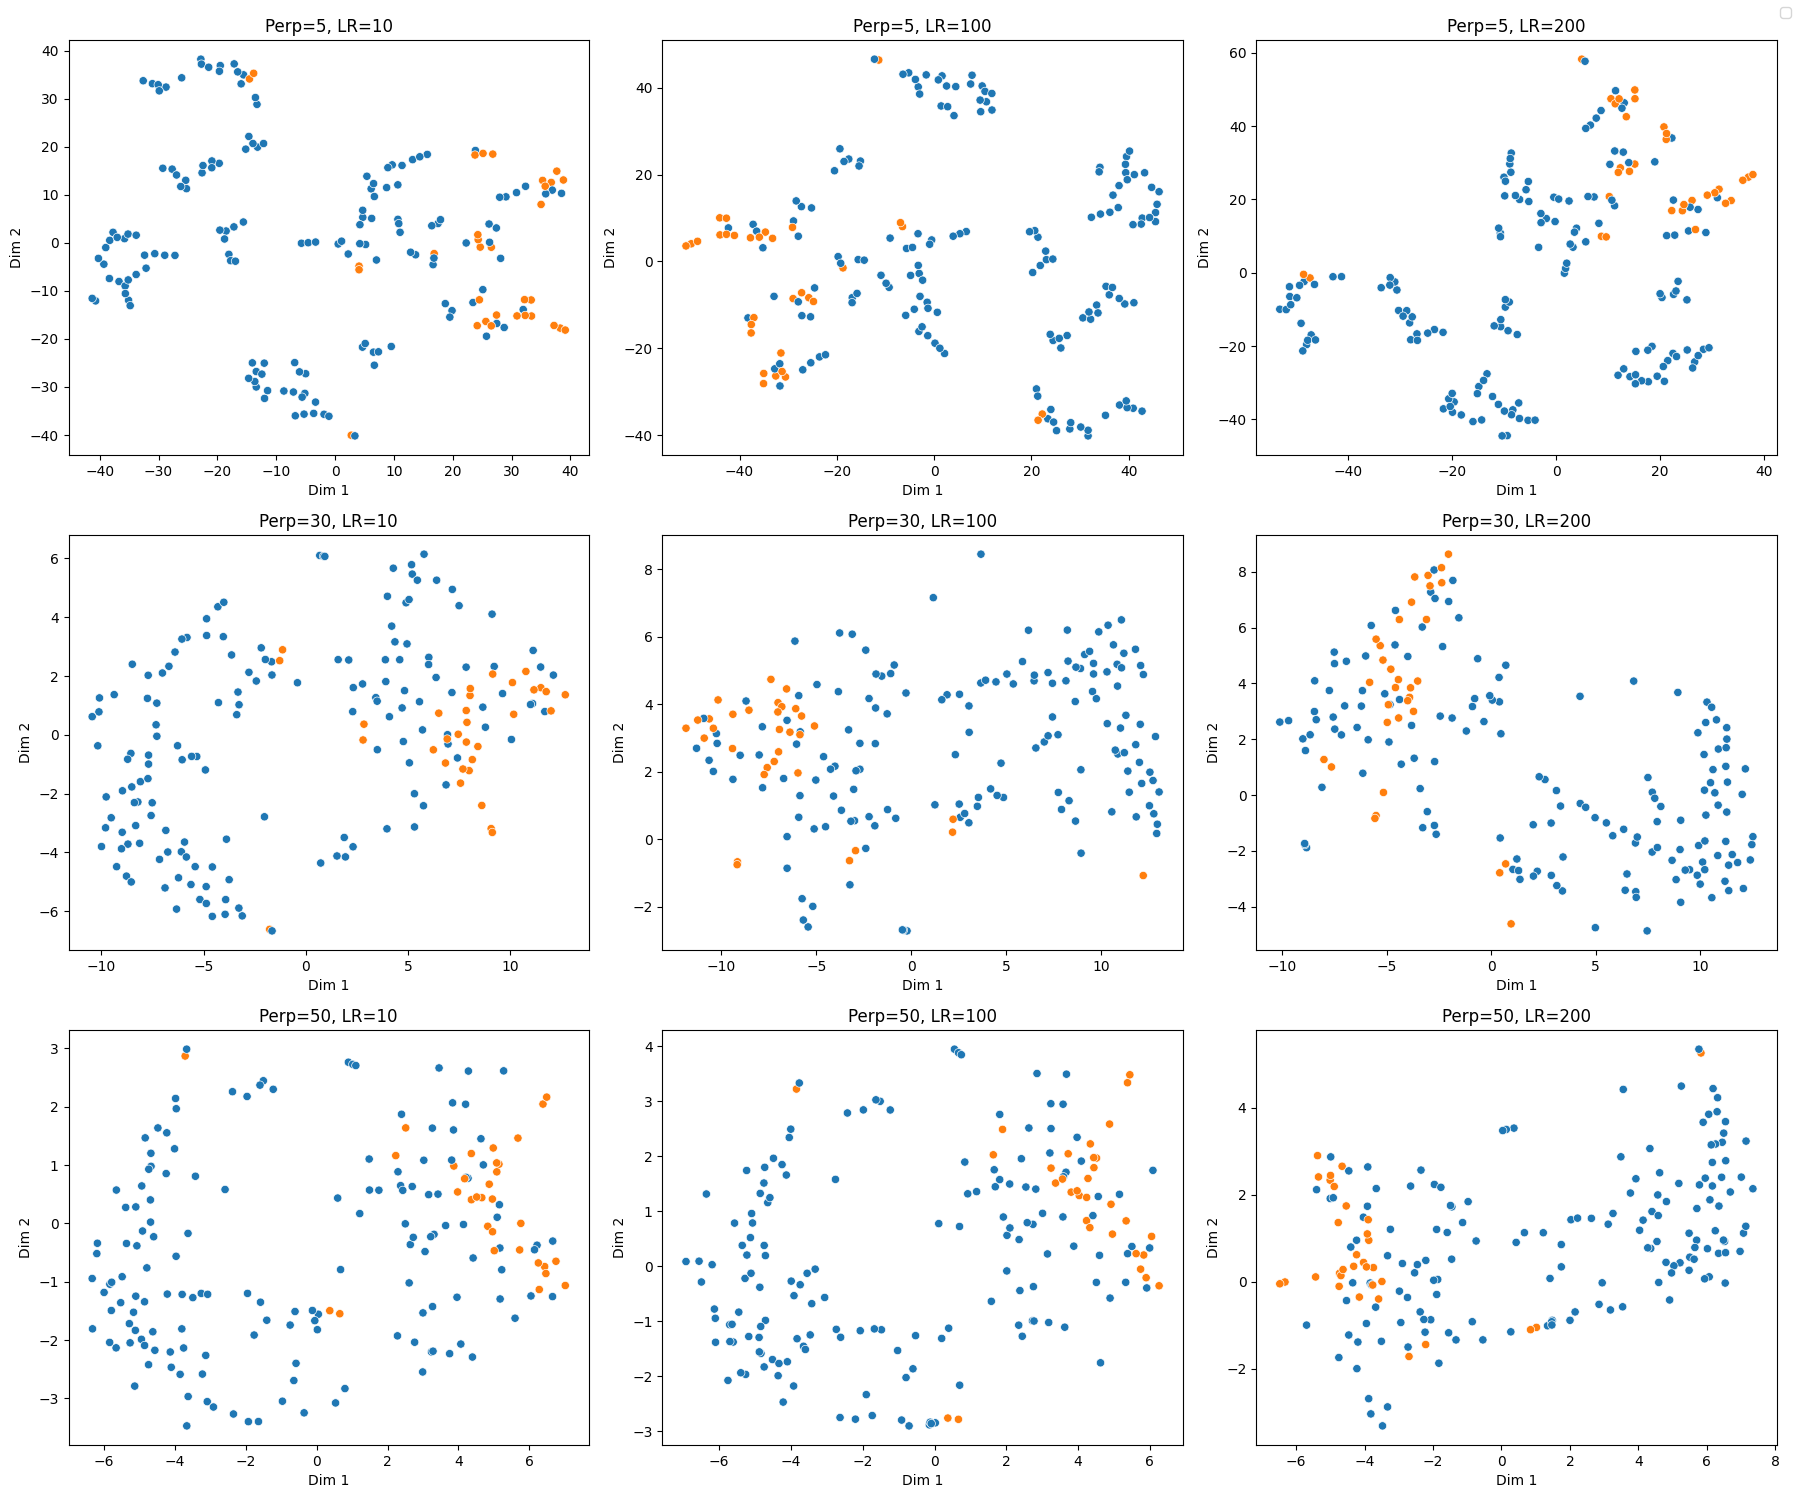

In [ ]:
#t-SNE with various perplexities and learning rates using subplots

perplexities = [5, 30, 50]
learning_rates = [10, 100, 200]

fig, axes = plt.subplots(len(perplexities), len(learning_rates), figsize=(18, 15))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(learning_rates):
        
        ax = axes[i, j]   # select subplot
        
        tsne = TSNE(
            n_components=2,
            perplexity=perp,
            learning_rate=lr,
            metric='cosine',
            random_state=42
        )
        
        tsne_result = tsne.fit_transform(scaled_data)
        
        sns.scatterplot(
            x=tsne_result[:,0],
            y=tsne_result[:,1],
            hue=status,
            ax=ax,
            legend=False   # Remove legend from each subplot 
        )
        
        ax.set_title(f"Perp={perp}, LR={lr}")
        ax.set_xlabel("Dim 1")
        ax.set_ylabel("Dim 2")

# Global legend outside plots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

plt.tight_layout()
plt.show()


**Question**: How does the perpexity parameter change the result of the t-SNE?

Answer:
The perplexity parameter(numerber of neighbor considered) in t-SNE influences the balance between local and global aspects of the data. A lower perplexity value (5-30) focuses more on local relationships, leading to tighter clusters that may capture small-scale structures in the data. Conversely, a higher perplexity value (50-100) emphasizes global relationships, which can result in a more spread-out representation that captures broader patterns. Adjusting the perplexity can significantly alter the visualization, affecting how clusters are formed and how well the overall structure of the data is represented.


**Question**: How does the learning rate parameter change the restul of the t-SNE?

Answer: 
The learning rate parameter in t-SNE affects the convergence and stability of the optimization process. A low learning rate (10-100) can lead to slow convergence and may cause the algorithm to get stuck in local minima, resulting in poorly defined clusters. On the other hand, a high learning rate ( 500-1000) can cause the optimization to overshoot, leading to erratic behavior and distorted cluster formations. An optimal learning rate (typically between 200-400) helps achieve a balance, allowing the algorithm to converge smoothly while preserving the structure of the data. Adjusting the learning rate can significantly impact the quality of the t-SNE visualization and the interpretability of the resulting clusters.

Select an 'optimal' t-SNE (i.e. with good values for the parameters perpelxity and learning rate). Plot the two dimensions and color the datapoints based on status and contient (bonus). 


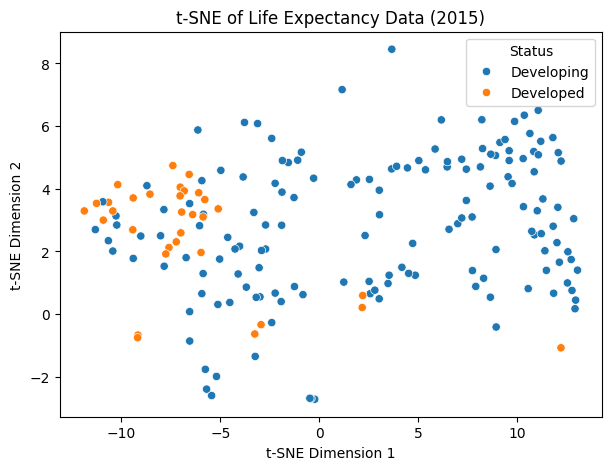

In [44]:
# plot the tSNE
tsne= TSNE(n_components=2, metric='cosine', random_state=42, learning_rate=100, perplexity=30)
tsne_result = tsne.fit_transform(scaled_data)
plt.figure(figsize=(7,5))  
sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=status)
plt.title('t-SNE of Life Expectancy Data (2015)')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.show()

**Question**: What insights can you derive from these plots? 

Answer:The t-SNE plot, generated using optimal parameters, reveal critical insights into the underlying similarity structure of the dataset. Regarding the Status variable, the analysis clearly indicates that the Developing countries are highly scattered and dispersed across the entire embedding, demonstrating substantial internal heterogeneity in the data. They do not form a distinct, coherent cluster but rather constitute the main underlying distribution. Furthermore, their heavy mixing with Developed countries confirms that the Status classification is a weak label that does not align with the true local similarity structure. 

### 5. Comparison

Compare the restuls of the 3 methods: PCA, MDS and t-SNE. Discuss their capability of capturing variation in the data, clustering it and if they are able to distinguish status ( and continent if you are using it).

Answer: 
PCA is effective in capturing the overall variance in the data and provides a linear transformation that highlights the main axes of variation. It is useful for identifying global patterns and relationships among variables. However, PCA may not capture complex, non-linear relationships in the data.

MDS, both metric and non-metric, focuses on preserving the pairwise distances between data points. Metric MDS maintains the actual distances, while non-metric MDS preserves the rank order of distances. Both methods are capable of revealing clusters and patterns in the data, with metric MDS providing a more faithful representation of the original distances. Non-metric MDS can be more flexible in capturing non-linear relationships but may distort the actual distances.
t-SNE excels at capturing local structures and revealing clusters in high-dimensional data. It is particularly effective for visualizing complex datasets and can uncover patterns that may not be apparent with linear methods like PCA. However, t-SNE can be sensitive to parameter choices (like perplexity and learning rate) and may not preserve global relationships as well as PCA or MDS.